# Old GMR sensor – 29.10.2026, slice 1, pl1
Load the pl1 recordings, plot raw / filtered example sweeps, the average of all bias ON sweeps (stimulus 100 µA), and the GMR average (baseline-subtracted) with the bias OFF average subtracted.

In [17]:
from pathlib import Path
import numpy as np
import matplotlib.pyplot as plt
import pyabf
from scipy.signal import butter, sosfiltfilt

DATA_DIR = Path("old_sensor_test/29102026")
FP, GMR = 0, 1          # channel 0 = IN 0 (mV), channel 1 = GMR (V)
CUTOFF_HZ = 1000        # low-pass cutoff
STIM_S = 0.2156         # stimulus time (s)
ARTIFACT_S = 0.0008     # stimulus artifact is over ~0.6 ms after stim
BASELINE_S = (STIM_S - 0.0055, STIM_S - 0.0005)  # pre-stimulus baseline window (s)
XLIM = (0.205, 0.260)   # zoom around the stimulus (s)

## Load recordings
`100uA` in the file names is the stimulus intensity, not the bias current. The `100uA_0000`–`0019` files are the bias ON run (bias OFF is labelled separately). `0018 (1)` is an identical copy of `0018` and is skipped.

In [18]:
pl1_files = sorted(f for f in DATA_DIR.glob("*pl1*.abf") if "(1)" not in f.name)
for f in pl1_files:
    print(f.name)

bias_on_files = sorted(DATA_DIR.glob("slice1_pl1_100uA_00??.abf"))
bias_off_files = sorted(DATA_DIR.glob("slice1_pl1_100uA_biasOFF_*.abf"))


def load_sweeps(files, channel):
    """All sweeps from the given files as a 2D array (n_sweeps, n_samples)."""
    sweeps = []
    for f in files:
        abf = pyabf.ABF(f)
        for i in abf.sweepList:
            abf.setSweep(i, channel=channel)
            sweeps.append(abf.sweepY.copy())
    return abf.sweepX, abf.dataRate, np.array(sweeps)


def lowpass(signal, fs, cutoff=CUTOFF_HZ, order=4):
    """Replace the stimulus artifact with a straight line, then low-pass filter."""
    signal = signal.copy()
    blank = (t >= STIM_S) & (t <= STIM_S + ARTIFACT_S)
    signal[blank] = np.interp(t[blank], t[~blank], signal[~blank])
    sos = butter(order, cutoff, btype="lowpass", fs=fs, output="sos")
    return sosfiltfilt(sos, signal)


def subtract_baseline(signal):
    """Subtract the mean of the pre-stimulus baseline window."""
    baseline = (t >= BASELINE_S[0]) & (t < BASELINE_S[1])
    return signal - signal[baseline].mean()


def ylim_without_artifact(ax, y):
    """Scale the y-axis to the response, not the (huge) stimulus artifact."""
    keep = (t >= XLIM[0]) & (t <= XLIM[1]) & ~((t >= STIM_S) & (t <= STIM_S + ARTIFACT_S))
    lo, hi = y[keep].min(), y[keep].max()
    pad = 0.1 * (hi - lo)
    ax.set_ylim(lo - pad, hi + pad)


t, fs, fp_on = load_sweeps(bias_on_files, FP)
_, _, gmr_on = load_sweeps(bias_on_files, GMR)
_, _, gmr_off = load_sweeps(bias_off_files, GMR)
print(f"bias ON: {len(gmr_on)} sweeps, bias OFF: {len(gmr_off)} sweeps")

slice1_pl1_0000.abf
slice1_pl1_100.abf
slice1_pl1_100uA_0000.abf
slice1_pl1_100uA_0001.abf
slice1_pl1_100uA_0002.abf
slice1_pl1_100uA_0003.abf
slice1_pl1_100uA_0004.abf
slice1_pl1_100uA_0005.abf
slice1_pl1_100uA_0006.abf
slice1_pl1_100uA_0007.abf
slice1_pl1_100uA_0008.abf
slice1_pl1_100uA_0009.abf
slice1_pl1_100uA_0010.abf
slice1_pl1_100uA_0011.abf
slice1_pl1_100uA_0012.abf
slice1_pl1_100uA_0013.abf
slice1_pl1_100uA_0014.abf
slice1_pl1_100uA_0015.abf
slice1_pl1_100uA_0016.abf
slice1_pl1_100uA_0017.abf
slice1_pl1_100uA_0018.abf
slice1_pl1_100uA_0019.abf
slice1_pl1_100uA_biasOFF_0001.abf
slice1_pl1_100uA_biasON_0000.abf
slice1_pl1_150uA_biasON_0000.abf
slice1_pl1_200uA_biasON_0000.abf
slice1_pl1_50uA_biasON_0000.abf
bias ON: 1000 sweeps, bias OFF: 50 sweeps


## Example sweep – raw

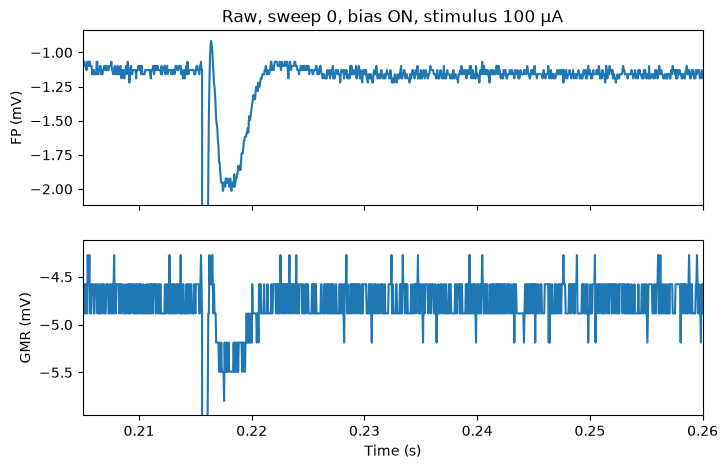

In [19]:
fig, axes = plt.subplots(2, 1, sharex=True, figsize=(8, 5))
axes[0].plot(t, fp_on[0])
axes[0].set_ylabel("FP (mV)")
ylim_without_artifact(axes[0], fp_on[0])
axes[1].plot(t, gmr_on[0] * 1e3)
axes[1].set_ylabel("GMR (mV)")
ylim_without_artifact(axes[1], gmr_on[0] * 1e3)
axes[1].set_xlabel("Time (s)")
axes[1].set_xlim(XLIM)
axes[0].set_title("Raw, sweep 0, bias ON, stimulus 100 µA")
plt.show()

## Example sweep – filtered

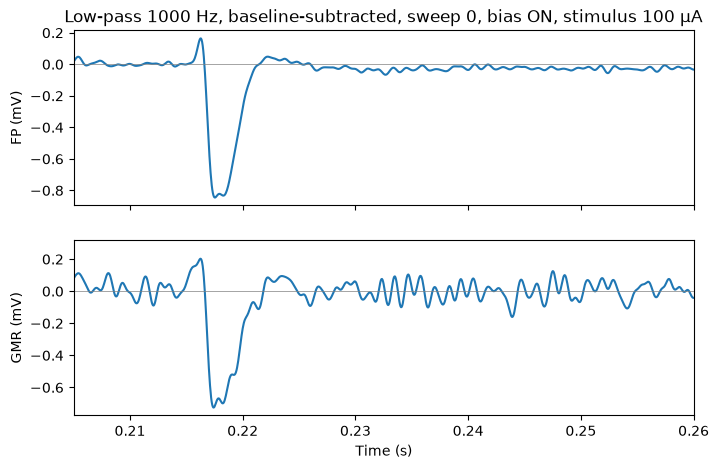

In [20]:
fp_filt = subtract_baseline(lowpass(fp_on[0], fs))
gmr_filt = subtract_baseline(lowpass(gmr_on[0], fs))

fig, axes = plt.subplots(2, 1, sharex=True, figsize=(8, 5))
axes[0].plot(t, fp_filt)
axes[0].axhline(0, color="grey", lw=0.5)
axes[0].set_ylabel("FP (mV)")
axes[1].plot(t, gmr_filt * 1e3)
axes[1].axhline(0, color="grey", lw=0.5)
axes[1].set_ylabel("GMR (mV)")
axes[1].set_xlabel("Time (s)")
axes[1].set_xlim(XLIM)
axes[0].set_title(f"Low-pass {CUTOFF_HZ} Hz, baseline-subtracted, sweep 0, bias ON, stimulus 100 µA")
plt.show()

## Average of all bias ON sweeps (stimulus 100 µA)

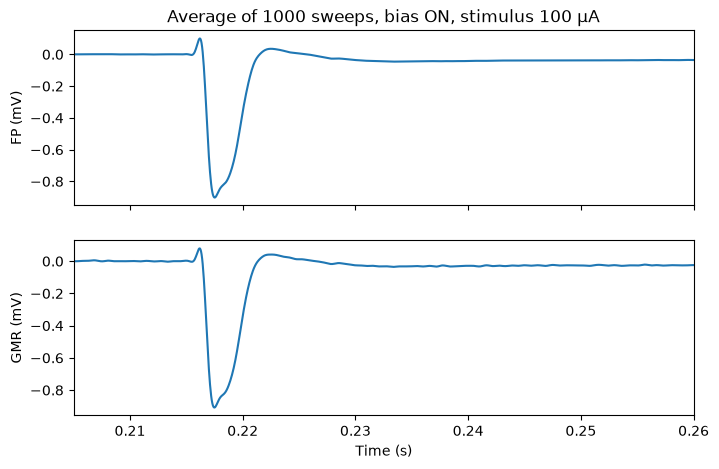

In [21]:
fp_on_mean = subtract_baseline(lowpass(fp_on.mean(axis=0), fs))
gmr_on_mean = subtract_baseline(lowpass(gmr_on.mean(axis=0), fs))

fig, axes = plt.subplots(2, 1, sharex=True, figsize=(8, 5))
axes[0].plot(t, fp_on_mean)
axes[0].set_ylabel("FP (mV)")
axes[1].plot(t, gmr_on_mean * 1e3)
axes[1].set_ylabel("GMR (mV)")
axes[1].set_xlabel("Time (s)")
axes[1].set_xlim(XLIM)
axes[0].set_title(f"Average of {len(gmr_on)} sweeps, bias ON, stimulus 100 µA")
plt.show()

## GMR: bias ON average − bias OFF average

Peak bias ON:  -0.908 mV
Peak bias OFF: -0.983 mV


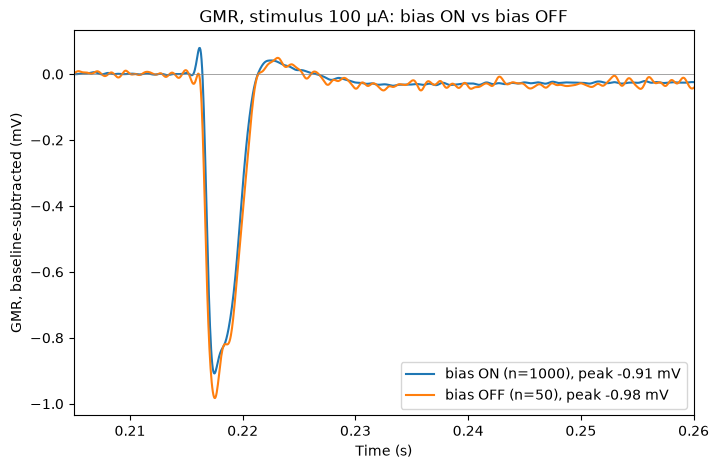

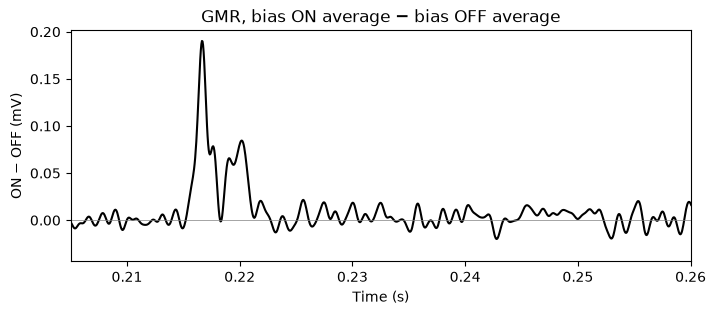

In [22]:
gmr_off_mean = subtract_baseline(lowpass(gmr_off.mean(axis=0), fs))
gmr_diff = gmr_on_mean - gmr_off_mean

# peak amplitude = most negative point in the first 10 ms after the artifact
response = (t > STIM_S + ARTIFACT_S) & (t < STIM_S + 0.010)
peak_on = gmr_on_mean[response].min() * 1e3
peak_off = gmr_off_mean[response].min() * 1e3
print(f"Peak bias ON:  {peak_on:.3f} mV")
print(f"Peak bias OFF: {peak_off:.3f} mV")

# ON and OFF overlaid, both baseline-subtracted so they start at 0
fig, ax = plt.subplots(figsize=(8, 5))
ax.plot(t, gmr_on_mean * 1e3, label=f"bias ON (n={len(gmr_on)}), peak {peak_on:.2f} mV")
ax.plot(t, gmr_off_mean * 1e3, label=f"bias OFF (n={len(gmr_off)}), peak {peak_off:.2f} mV")
ax.axhline(0, color="grey", lw=0.5)
ax.set_xlim(XLIM)
ax.set_xlabel("Time (s)")
ax.set_ylabel("GMR, baseline-subtracted (mV)")
ax.set_title("GMR, stimulus 100 µA: bias ON vs bias OFF")
ax.legend()
plt.show()

# difference
fig, ax = plt.subplots(figsize=(8, 3))
ax.plot(t, gmr_diff * 1e3, color="k")
ax.axhline(0, color="grey", lw=0.5)
ax.set_xlim(XLIM)
ax.set_xlabel("Time (s)")
ax.set_ylabel("ON − OFF (mV)")
ax.set_title("GMR, bias ON average − bias OFF average")
plt.show()

## Correlation between GMR and FP
If the GMR channel only picks up the field potential electrically, GMR and FP have the same shape and the points lie on a straight line (r ≈ 1), for both bias ON and bias OFF.
A magnetic signal would only appear with bias ON, and would show up as a deviation from the line.

In [ ]:
_, _, fp_off = load_sweeps(bias_off_files, FP)
fp_off_mean = subtract_baseline(lowpass(fp_off.mean(axis=0), fs))

window = (t > STIM_S + ARTIFACT_S) & (t < STIM_S + 0.030)   # 30 ms after the artifact

fig, axes = plt.subplots(1, 2, figsize=(12, 4.5))

# left: GMR vs FP, sample by sample in the response window
ax = axes[0]
for name, fp_mean, gmr_mean, color in [("bias ON", fp_on_mean, gmr_on_mean, "tab:blue"),
                                       ("bias OFF", fp_off_mean, gmr_off_mean, "tab:orange")]:
    x, y = fp_mean[window], gmr_mean[window] * 1e3
    r = np.corrcoef(x, y)[0, 1]
    ax.plot(x, y, ".", ms=3, color=color, alpha=0.6, label=f"{name}: r = {r:.4f}")
lims = [min(ax.get_xlim()[0], ax.get_ylim()[0]), max(ax.get_xlim()[1], ax.get_ylim()[1])]
ax.plot(lims, lims, "k--", lw=0.6, label="GMR = FP")
ax.set_xlabel("FP, baseline-subtracted (mV)")
ax.set_ylabel("GMR, baseline-subtracted (mV)")
ax.set_title("GMR vs FP, 0–30 ms after stimulus")
ax.set_aspect("equal")
ax.legend(fontsize=8)

# right: FP and GMR overlaid in time (bias ON)
ax = axes[1]
ax.plot(t * 1e3, fp_on_mean, color="k", lw=1.5, label="FP")
ax.plot(t * 1e3, gmr_on_mean * 1e3, color="tab:blue", lw=1, label="GMR (bias ON)")
ax.plot(t * 1e3, gmr_off_mean * 1e3, color="tab:orange", lw=1, label="GMR (bias OFF)")
ax.axhline(0, color="grey", lw=0.5)
ax.set_xlim(XLIM[0] * 1e3, XLIM[1] * 1e3)
ax.set_xlabel("Time (ms)")
ax.set_ylabel("mV")
ax.set_title("FP and GMR averages overlaid")
ax.legend(fontsize=8)

fig.tight_layout()
plt.show()

## I/O curve, position pl1 (bias ON)
Peak amplitude of the response (most negative point 0.8–6 ms after the stimulus), mean ± SD over sweeps, for the FP and GMR channels.
The response peaks only ~1.5 ms after the stimulus and is over by ~5 ms, much faster than a synaptic fEPSP. The right panel compares its time course with the SR fEPSP from 12.08 (rec 10, 250 µA).

FP   50 µA: peak = -0.450 ± 0.016 mV (n = 12 sweeps)
FP  100 µA: peak = -0.800 ± 0.016 mV (n = 8 sweeps)
FP  150 µA: peak = -1.656 ± 0.016 mV (n = 8 sweeps)
FP  200 µA: peak = -1.946 ± 0.030 mV (n = 10 sweeps)
GMR  50 µA: peak = -0.527 ± 0.039 mV (n = 12 sweeps)
GMR 100 µA: peak = -0.799 ± 0.060 mV (n = 8 sweeps)
GMR 150 µA: peak = -1.684 ± 0.053 mV (n = 8 sweeps)
GMR 200 µA: peak = -1.969 ± 0.068 mV (n = 10 sweeps)


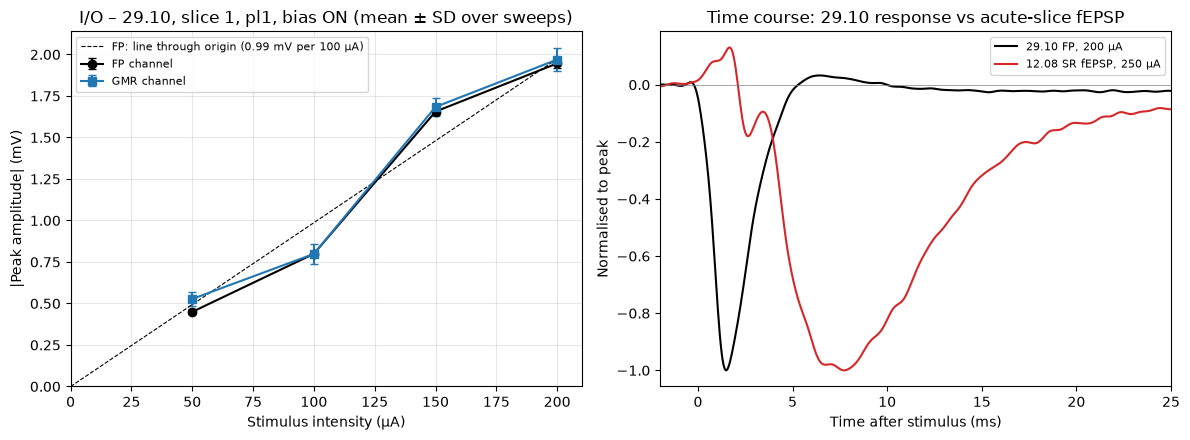

In [24]:
from fp_analysis import stim_time_s, preprocess

IO_FILES = {50: "slice1_pl1_50uA_biasON_0000.abf",
            100: "slice1_pl1_100uA_biasON_0000.abf",   # different protocol (5 s sweeps), stim time read from file
            150: "slice1_pl1_150uA_biasON_0000.abf",
            200: "slice1_pl1_200uA_biasON_0000.abf"}
PEAK_WINDOW_S = (0.0008, 0.006)  # after the stimulus (artifact is blanked up to 0.8 ms)
ACUTE_REF = Path("acute") / "120826" / "12082026_FP_SR_cell2_activation_0010.abf"   # 12.08 SR, 250 µA


def io_sweeps(path, channel):
    """Preprocessed sweeps (mV) of one channel, time relative to the stimulus (s)."""
    abf = pyabf.ABF(path)
    stim = stim_time_s(abf)
    scale = 1e3 if channel == GMR else 1.0          # GMR channel is in V
    sweeps = []
    for i in abf.sweepList:
        abf.setSweep(i, channel=channel)
        sweeps.append(preprocess(abf.sweepX, abf.sweepY * scale, stim, abf.dataRate))
    return abf.sweepX - stim, np.array(sweeps)


io = {}
for name, channel in [("FP", FP), ("GMR", GMR)]:
    rows = []
    for uA, fname in sorted(IO_FILES.items()):
        tt, sw = io_sweeps(DATA_DIR / fname, channel)
        w = (tt >= PEAK_WINDOW_S[0]) & (tt <= PEAK_WINDOW_S[1])
        peaks = sw[:, w].min(axis=1)
        rows.append((uA, peaks.mean(), peaks.std(), len(sw)))
        print(f"{name:3s} {uA:3d} µA: peak = {peaks.mean():6.3f} ± {peaks.std():.3f} mV (n = {len(sw)} sweeps)")
    io[name] = np.array(rows)

fig, axes = plt.subplots(1, 2, figsize=(12, 4.5))

ax = axes[0]
for name, color, marker in [("FP", "k", "o"), ("GMR", "tab:blue", "s")]:
    x, y, sd, n = io[name].T
    ax.errorbar(x, -y, yerr=sd, marker=marker, color=color, capsize=3, label=f"{name} channel")
x, y = io["FP"][:, 0], -io["FP"][:, 1]
k = np.dot(x, y) / np.dot(x, x)                       # straight line through the origin
xs = np.array([0, x.max()])
ax.plot(xs, k * xs, "k--", lw=0.8, label=f"FP: line through origin ({k*100:.2f} mV per 100 µA)")
ax.set_xlim(0, None)
ax.set_ylim(0, None)
ax.set_xlabel("Stimulus intensity (µA)")
ax.set_ylabel("|Peak amplitude| (mV)")
ax.set_title("I/O – 29.10, slice 1, pl1, bias ON (mean ± SD over sweeps)")
ax.legend(fontsize=8)
ax.grid(alpha=0.3)

ax = axes[1]
tt, sw = io_sweeps(DATA_DIR / IO_FILES[200], FP)
m = sw.mean(axis=0)
ax.plot(tt * 1e3, m / abs(m[(tt >= PEAK_WINDOW_S[0]) & (tt <= PEAK_WINDOW_S[1])].min()), color="k", label="29.10 FP, 200 µA")
ta, swa = io_sweeps(ACUTE_REF, 0)
ma = swa[1:].mean(axis=0)                              # first sweep skipped, as in acute_slices_sr.py
ax.plot(ta * 1e3, ma / abs(ma[(ta >= 0.003) & (ta <= 0.015)].min()), color="tab:red", label="12.08 SR fEPSP, 250 µA")
ax.axhline(0, color="grey", lw=0.5)
ax.set_xlim(-2, 25)
ax.set_xlabel("Time after stimulus (ms)")
ax.set_ylabel("Normalised to peak")
ax.set_title("Time course: 29.10 response vs acute-slice fEPSP")
ax.legend(fontsize=8)

fig.tight_layout()
plt.show()

## Laminar profile (positions pl1–pl6, stimulus 100 µA, bias ON)
Mean traces at each position (left: FP channel, right: GMR channel). The peak of the early response (0.8–6 ms after the stimulus) is printed for each position. The orange band (6–20 ms) marks where a synaptic fEPSP would be.
Fill in `POSITIONS` with the layer or depth of each position. A synaptic fEPSP would reverse polarity between layers (sink in SR, source in SP); a stimulus artifact only gets smaller with distance.

pl1: FP peak -0.800 mV, GMR peak -0.799 mV (n = 8 sweeps)
pl2: FP peak -1.624 mV, GMR peak -1.639 mV (n = 20 sweeps)
pl3: FP peak -0.603 mV, GMR peak -0.681 mV (n = 8 sweeps)
pl4: FP peak -0.649 mV, GMR peak -0.734 mV (n = 7 sweeps)
pl5: FP peak -0.484 mV, GMR peak -0.585 mV (n = 2 sweeps)
pl6: FP peak -0.284 mV, GMR peak -0.378 mV (n = 8 sweeps)


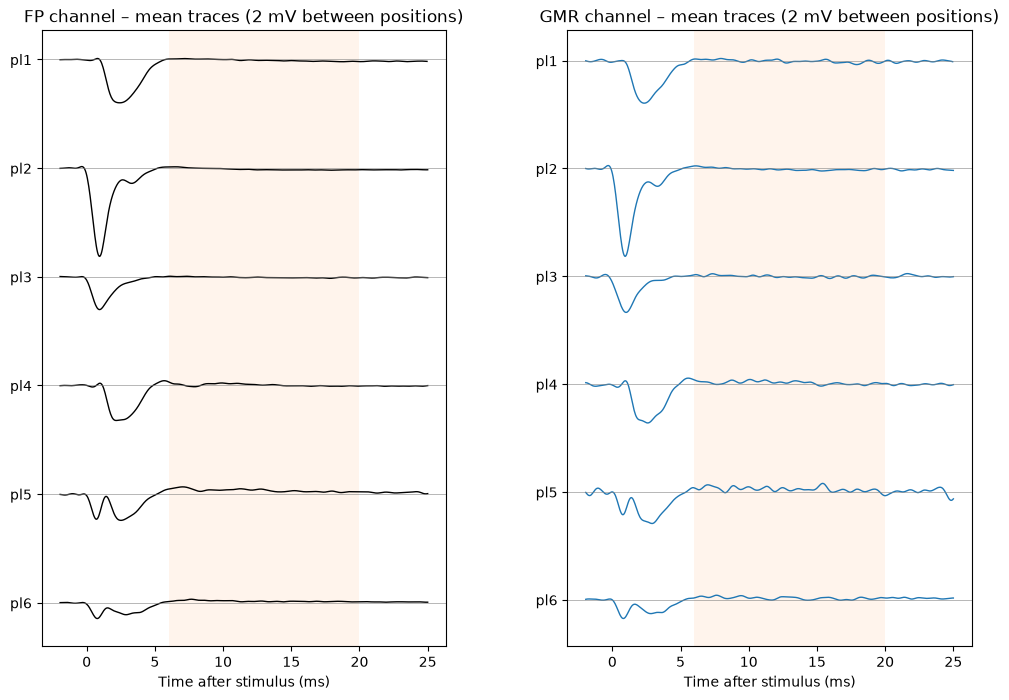

In [25]:
from fp_analysis import stim_time_s, preprocess

# position -> label on the y-axis (fill in layer / depth, e.g. "pl1 – SR", or "pl1 – 200 µm")
POSITIONS = {"pl1": "pl1", "pl2": "pl2", "pl3": "pl3", "pl4": "pl4", "pl5": "pl5", "pl6": "pl6"}
EARLY_S = (0.0008, 0.006)     # early response (artifact blanked up to 0.8 ms)
LATE_S = (0.006, 0.020)       # where a synaptic fEPSP would be
LAM_OFFSET = 2.0              # vertical spacing between stacked traces (mV)


def position_sweeps(pos, channel):
    """Preprocessed sweeps (mV) at one position, 100 µA, bias ON; time relative to stimulus (s)."""
    path = sorted(DATA_DIR.glob(f"slice1_{pos}_100uA_biasON_*.abf"))[0]
    abf = pyabf.ABF(path)
    stim = stim_time_s(abf)
    scale = 1e3 if channel == GMR else 1.0          # GMR channel is in V
    sweeps = []
    for i in abf.sweepList:
        abf.setSweep(i, channel=channel)
        sweeps.append(preprocess(abf.sweepX, abf.sweepY * scale, stim, abf.dataRate))
    return abf.sweepX - stim, np.array(sweeps)


lam = {}
for pos in POSITIONS:
    for name, channel in [("FP", FP), ("GMR", GMR)]:
        tt, sw = position_sweeps(pos, channel)
        early = (tt >= EARLY_S[0]) & (tt <= EARLY_S[1])
        peaks = sw[:, early].min(axis=1)
        lam[pos, name] = dict(t=tt, mean=sw.mean(axis=0), peak=peaks.mean(), sd=peaks.std(), n=len(sw))
    print(f"{pos}: FP peak {lam[pos, 'FP']['peak']:6.3f} mV, GMR peak {lam[pos, 'GMR']['peak']:6.3f} mV "
          f"(n = {lam[pos, 'FP']['n']} sweeps)")

fig, axes = plt.subplots(1, 2, figsize=(12, 8), sharex=True)
fig.subplots_adjust(wspace=0.3)
labels = list(POSITIONS.values())
for ax, name in zip(axes, ["FP", "GMR"]):
    for k, pos in enumerate(POSITIONS):
        d = lam[pos, name]
        show = (d["t"] >= -0.002) & (d["t"] <= 0.025)
        ax.plot(d["t"][show] * 1e3, d["mean"][show] - k * LAM_OFFSET, color="k" if name == "FP" else "tab:blue", lw=1)
        ax.axhline(-k * LAM_OFFSET, color="grey", lw=0.4)
    ax.axvspan(LATE_S[0] * 1e3, LATE_S[1] * 1e3, color="tab:orange", alpha=0.08, lw=0)
    ax.set_yticks([-k * LAM_OFFSET for k in range(len(labels))])
    ax.set_yticklabels(labels)
    ax.set_xlabel("Time after stimulus (ms)")
    ax.set_title(f"{name} channel – mean traces ({LAM_OFFSET:g} mV between positions)")
plt.show()

## Stimulus artifact: 29.10 (sensor setup) vs 12.08 (standard rig)
Raw FP channel, mean over sweeps, baseline-subtracted, **no artifact blanking or filtering**.
Left: |signal| on a log scale. Middle: zoom on ±2 mV, where the response is measured. Right: artifact peak vs stimulus intensity.
In 29.10 the artifact is ~1 V (the FP channel saturates at −1000 mV) and grows linearly with the current, which points to the whole bath shifting potential (poor bath ground / stimulus current return path) rather than a local field around the stimulating electrode.

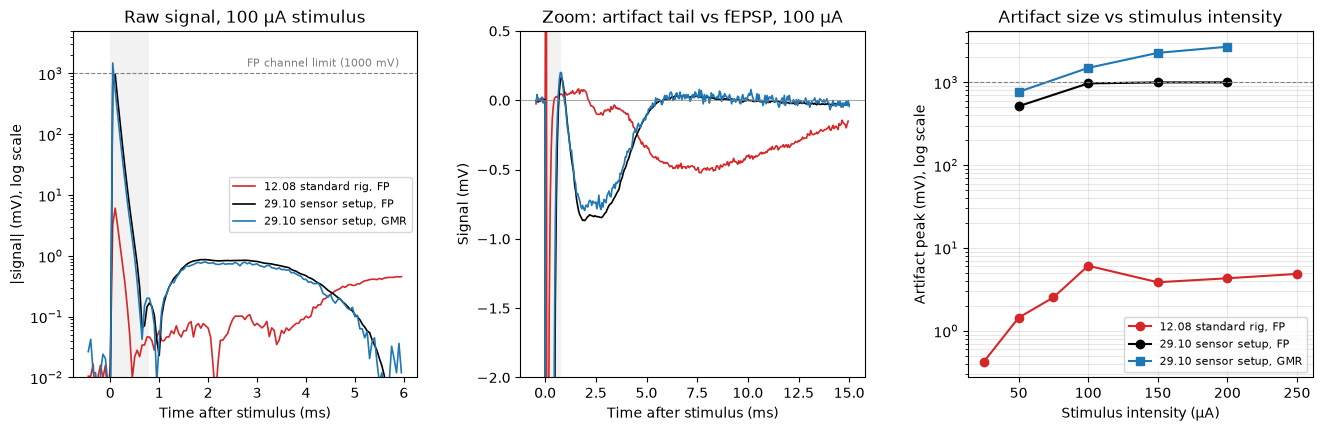

50 µA: 12.08 1.4 mV, 29.10 FP 515 mV (357x, FP saturates at 1000 mV), 29.10 GMR 768 mV
100 µA: 12.08 6.1 mV, 29.10 FP 971 mV (159x, FP saturates at 1000 mV), 29.10 GMR 1494 mV
150 µA: 12.08 3.9 mV, 29.10 FP 998 mV (259x, FP saturates at 1000 mV), 29.10 GMR 2269 mV
200 µA: 12.08 4.3 mV, 29.10 FP 998 mV (232x, FP saturates at 1000 mV), 29.10 GMR 2689 mV


In [27]:
ART_ACUTE = Path("acute") / "120826"
ART_ACUTE_FILES = {25: "07", 50: "06", 75: "05", 100: "04", 150: "08", 200: "09", 250: "10"}   # µA -> rec
ART_SENSOR_FILES = {50: "slice1_pl1_50uA_biasON_0000.abf", 100: "slice1_pl1_100uA_0000.abf",
                    150: "slice1_pl1_150uA_biasON_0000.abf", 200: "slice1_pl1_200uA_biasON_0000.abf"}
FP_LIMIT_MV = 1000            # FP channel saturates here


def raw_mean(path, channel=0, scale=1.0):
    """Raw mean over sweeps (no blanking / filtering), baseline-subtracted; time relative to stimulus (ms)."""
    abf = pyabf.ABF(path)
    stim = stim_time_s(abf)
    sweeps = []
    for i in abf.sweepList:
        abf.setSweep(i, channel=channel)
        sweeps.append(abf.sweepY * scale)
    m = np.mean(sweeps, axis=0)
    t = (abf.sweepX - stim) * 1e3
    return t, m - m[(t > -5) & (t < -0.5)].mean()


traces = {"12.08 standard rig, FP": (raw_mean(ART_ACUTE / f"12082026_FP_SR_cell2_activation_00{ART_ACUTE_FILES[100]}.abf"), "tab:red"),
          "29.10 sensor setup, FP": (raw_mean(DATA_DIR / ART_SENSOR_FILES[100], FP), "k"),
          "29.10 sensor setup, GMR": (raw_mean(DATA_DIR / ART_SENSOR_FILES[100], GMR, 1e3), "tab:blue")}

fig, axes = plt.subplots(1, 3, figsize=(16, 4.5))
fig.subplots_adjust(wspace=0.3)

ax = axes[0]
for label, ((tt, m), color) in traces.items():
    show = (tt >= -0.5) & (tt <= 6)
    ax.semilogy(tt[show], np.abs(m[show]) + 1e-3, color=color, lw=1.2, label=label)
ax.axhline(FP_LIMIT_MV, color="grey", ls="--", lw=0.8)
ax.text(5.9, FP_LIMIT_MV * 1.3, "FP channel limit (1000 mV)", ha="right", fontsize=8, color="grey")
ax.axvspan(0, 0.8, color="grey", alpha=0.1, lw=0)
ax.set_ylim(1e-2, 5e3)
ax.set_xlabel("Time after stimulus (ms)")
ax.set_ylabel("|signal| (mV), log scale")
ax.set_title("Raw signal, 100 µA stimulus")
ax.legend(fontsize=8)

ax = axes[1]
for label, ((tt, m), color) in traces.items():
    show = (tt >= -0.5) & (tt <= 15)
    ax.plot(tt[show], m[show], color=color, lw=1.2, label=label)
ax.axhline(0, color="grey", lw=0.5)
ax.axvspan(0, 0.8, color="grey", alpha=0.1, lw=0)
ax.set_ylim(-2, 0.5)
ax.set_xlabel("Time after stimulus (ms)")
ax.set_ylabel("Signal (mV)")
ax.set_title("Zoom: artifact tail vs fEPSP, 100 µA")

ax = axes[2]
acute_peaks = {uA: -raw_mean(ART_ACUTE / f"12082026_FP_SR_cell2_activation_00{rec}.abf")[1].min()
               for uA, rec in ART_ACUTE_FILES.items()}
sensor_fp = {uA: -raw_mean(DATA_DIR / f, FP)[1].min() for uA, f in ART_SENSOR_FILES.items()}
sensor_gmr = {uA: -raw_mean(DATA_DIR / f, GMR, 1e3)[1].min() for uA, f in ART_SENSOR_FILES.items()}
for peaks, label, color, marker in [(acute_peaks, "12.08 standard rig, FP", "tab:red", "o"),
                                    (sensor_fp, "29.10 sensor setup, FP", "k", "o"),
                                    (sensor_gmr, "29.10 sensor setup, GMR", "tab:blue", "s")]:
    x = sorted(peaks)
    ax.semilogy(x, [peaks[u] for u in x], marker=marker, color=color, label=label)
ax.axhline(FP_LIMIT_MV, color="grey", ls="--", lw=0.8)
ax.set_xlabel("Stimulus intensity (µA)")
ax.set_ylabel("Artifact peak (mV), log scale")
ax.set_title("Artifact size vs stimulus intensity")
ax.legend(fontsize=8)
ax.grid(alpha=0.3, which="both")

plt.show()

for uA in sorted(sensor_fp):
    if uA in acute_peaks:
        print(f"{uA} µA: 12.08 {acute_peaks[uA]:.1f} mV, 29.10 FP {sensor_fp[uA]:.0f} mV "
              f"({sensor_fp[uA] / acute_peaks[uA]:.0f}x, FP saturates at {FP_LIMIT_MV} mV), 29.10 GMR {sensor_gmr[uA]:.0f} mV")

## Time course: response and GMR/FP coupling over the session (pl1, 100 µA)
Each dot is one sweep, large markers are mean ± SD per file; files are placed by their recording time.
Bottom: k = GMR/FP (least-squares slope of the mean traces, 0.8–10 ms). If the GMR channel contained a magnetic component, k would drop when the bias is switched off.
Note: bias OFF (18:48) was recorded *after* the bias ON run, not before.

In [ ]:
from fp_analysis import stim_time_s, preprocess

# all pl1, 100 µA files in recording order (bias OFF marked separately)
TC_FILES = (["slice1_pl1_100uA_biasON_0000.abf", "slice1_pl1_100.abf"]
            + [f"slice1_pl1_100uA_{i:04d}.abf" for i in range(20)]
            + ["slice1_pl1_100uA_biasOFF_0001.abf"])
TC_EARLY_S = (0.0008, 0.006)   # early response window after the stimulus
TC_K_S = (0.0008, 0.010)       # window for the GMR-vs-FP slope k

tc = []
t0 = None
for fname in TC_FILES:
    abf = pyabf.ABF(DATA_DIR / fname)
    stim = stim_time_s(abf)
    start = abf.abfDateTime
    t0 = t0 or start
    sw = {}
    for name, channel, scale in [("FP", FP, 1.0), ("GMR", GMR, 1e3)]:
        rows = []
        for i in abf.sweepList:
            abf.setSweep(i, channel=channel)
            rows.append(preprocess(abf.sweepX, abf.sweepY * scale, stim, abf.dataRate))
        sw[name] = np.array(rows)
    tt = abf.sweepX - stim
    early = (tt >= TC_EARLY_S[0]) & (tt <= TC_EARLY_S[1])
    kwin = (tt >= TC_K_S[0]) & (tt <= TC_K_S[1])
    fp_m, gmr_m = sw["FP"].mean(axis=0)[kwin], sw["GMR"].mean(axis=0)[kwin]
    sweep_min = (start - t0).total_seconds() / 60 + np.arange(len(abf.sweepList)) * abf.sweepIntervalSec / 60
    tc.append(dict(name=fname, off="biasOFF" in fname, minutes=sweep_min,
                   fp=sw["FP"][:, early].min(axis=1), gmr=sw["GMR"][:, early].min(axis=1),
                   k=np.dot(fp_m, gmr_m) / np.dot(fp_m, fp_m),
                   t_mid=sweep_min.mean()))
    print(f"{start:%H:%M}  {fname:36s} FP {tc[-1]['fp'].mean():6.3f} mV  GMR {tc[-1]['gmr'].mean():6.3f} mV  k {tc[-1]['k']:.3f}")

fig, axes = plt.subplots(3, 1, sharex=True, figsize=(10, 8))
fig.subplots_adjust(hspace=0.15)
for d in tc:
    color = "tab:orange" if d["off"] else "tab:blue"
    axes[0].plot(d["minutes"], d["fp"], ".", ms=2.5, color=color, alpha=0.5)
    axes[0].errorbar(d["t_mid"], d["fp"].mean(), yerr=d["fp"].std(), fmt="o", ms=4, color=color, capsize=2)
    axes[1].plot(d["minutes"], d["gmr"], ".", ms=2.5, color=color, alpha=0.5)
    axes[1].errorbar(d["t_mid"], d["gmr"].mean(), yerr=d["gmr"].std(), fmt="o", ms=4, color=color, capsize=2)
    axes[2].plot(d["t_mid"], d["k"], "o", ms=5, color=color)
axes[0].set_ylabel("FP peak (mV)")
axes[1].set_ylabel("GMR peak (mV)")
axes[2].set_ylabel("k = GMR / FP")
axes[2].set_xlabel(f"Time since first recording ({t0:%H:%M}) (min)")
axes[0].set_title("pl1, stimulus 100 µA: early response (0.8–6 ms) and GMR/FP coupling over time")
axes[0].plot([], [], "o", color="tab:blue", label="bias ON")
axes[0].plot([], [], "o", color="tab:orange", label="bias OFF")
axes[0].legend(fontsize=8)
for ax in axes:
    ax.grid(alpha=0.3)
plt.show()
